In [1]:
#import libraries 
import os 
import pandas as pd 
from datasets import load_dataset 
import matplotlib.pyplot as plt 
import ast

#path for local caching 

file_path="data_jobs.parquet"

#loading data 
if not os.path.exists(file_path):
    dataset=load_dataset('lukebarousse/data_jobs') 
    df=dataset['train'].to_pandas()
    df.to_parquet(file_path)
else:
    df=pd.read_parquet(file_path)

#data cleanup 
df['job_posted_date']=pd.to_datetime(df['job_posted_date'])
df['job_skills']=df['job_skills'].apply(lambda skill_list2: ast.literal_eval(skill_list2) if isinstance(skill_list2,str) else skill_list2 )


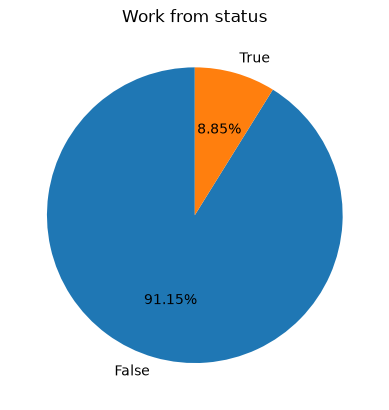

In [15]:
df['job_work_from_home'].value_counts().plot(kind='pie',startangle=90,autopct='%1.2f%%')
plt.title('Work from status')
plt.ylabel("")
plt.show()

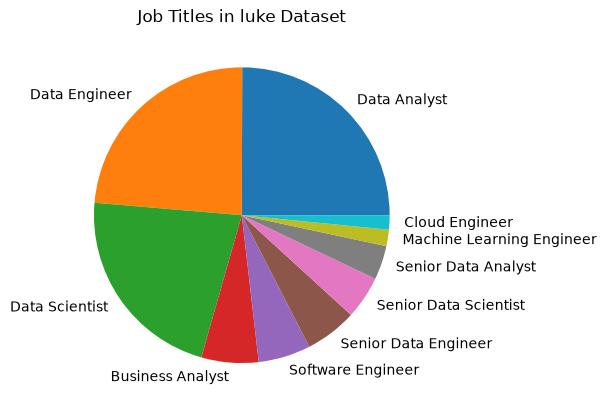

In [6]:
df['job_title_short'].value_counts().plot(kind='pie')
plt.title('Job Titles in luke Dataset')
plt.ylabel("")
plt.show()

In [16]:
df[['job_work_from_home','job_no_degree_mention','job_health_insurance']]

,job_work_from_home,job_no_degree_mention,job_health_insurance
0,False,False,False
1,False,False,False
2,False,False,False
3,False,True,False
4,False,False,False
...,...,...,...
785736,False,False,False
785737,False,False,False
785738,False,False,False
785739,False,False,False


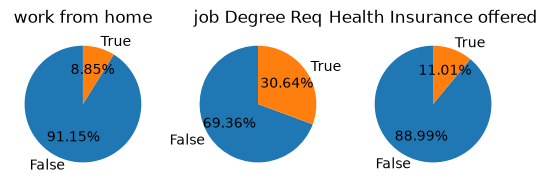

In [23]:
fig,ax=plt.subplots(1,3)
dict_column={
    'job_work_from_home':'work from home',
    'job_no_degree_mention':'job Degree Req',
    'job_health_insurance':'Health Insurance offered'
}
for i,(column,title) in enumerate(dict_column.items()):
    ax[i].pie(df[column].value_counts(),startangle=90,autopct='%1.2f%%',labels=['False','True'])
    ax[i].set_title(title)
plt.show()